# IRWA Final Project — Part 1: Text Processing and Exploratory Data Analysis

Corpus: e-commerce fashion products dataset (data/fashion_products_dataset.json).

In [1]:
import json
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import ne_chunk, pos_tag
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize
from wordcloud import WordCloud

for res in ["stopwords", "punkt", "punkt_tab", "averaged_perceptron_tagger_eng", "maxent_ne_chunker_tab", "words"]:
    nltk.download(res, quiet=True)

## PART 1: Data preparation

### 1.1 Loading and first inspection

In [2]:
with open("../../data/fashion_products_dataset.json", encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

print("Products:", df.shape[0], "| Fields:", df.shape[1])
print("Duplicated pid:", df["pid"].duplicated().sum())
df.head(2)

Products: 28080 | Fields: 17
Duplicated pid: 0


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...


In [3]:
def is_empty(value):
    """Return True for empty strings, empty lists and NaN."""
    if isinstance(value, list):
        return len(value) == 0
    if isinstance(value, float):
        return np.isnan(value)
    return isinstance(value, str) and value.strip() == ""


missing = df.apply(lambda col: col.map(is_empty).sum())
pd.DataFrame({"missing": missing, "%": (100 * missing / len(df)).round(2)}).sort_values("missing", ascending=False)

,missing,%
description,11150,39.71
average_rating,2261,8.05
brand,2009,7.15
seller,1643,5.85
discount,855,3.04
actual_price,777,2.77
images,772,2.75
selling_price,2,0.01
product_details,0,0.00
title,0,0.00


### 1.2 Pre-processing of the text fields (title, description)

Required steps: **tokenization, punctuation removal, stop-word removal, stemming** (NLTK Porter stemmer).

Additional steps:

| Step | Reason |
|---|---|
| Lowercasing | `Cotton` and `cotton` must be the same term |
| Remove non-ASCII characters | Emojis and special symbols in seller-written descriptions |
| Split words glued by punctuation (`look.Designed` → `look designed`) | Very frequent in the scraped descriptions |
| Remove possessive `'s` (`women's` → `women`) | Gender words are important in queries |
| Normalise `t-shirt` / `t shirt` → `tshirt` | The same product type is written in three different ways |
| Remove tokens containing digits and 1-character tokens | Style codes (`1005combo2`), quantities and leftovers like `s`; numeric information is handled as numeric fields |

men and women are not stop words, so they are kept (they are key in the validation queries).
The same function must be applied to the queries in the next parts.

In [4]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
PUNCT_TABLE = str.maketrans({c: " " for c in string.punctuation})


def preprocess(text, stem=True):
    """Clean, tokenize, remove punctuation/stop words/digit tokens and (optionally) stem a string."""
    if not isinstance(text, str):
        return []
    text = text.encode("ascii", "ignore").decode("ascii").lower()
    text = re.sub(r"'s\b", "", text)
    text = re.sub(r"\bt[\s-]?shirts?\b", "tshirt", text)
    text = text.translate(PUNCT_TABLE)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1 and not any(c.isdigit() for c in t)]
    if stem:
        tokens = [STEMMER.stem(t) for t in tokens]
    return tokens


example = df.loc[0, "description"]
print("RAW      :", example)
print("PROCESSED:", preprocess(example))
print()
print("query_1  :", preprocess("women full sleeve sweatshirt cotton"))
print("query_2  :", preprocess("men slim jeans blue"))

RAW      : Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
PROCESSED: ['yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']

query_1  : ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
query_2  : ['men', 'slim', 'jean', 'blue']


### 1.3 Fields returned for each document

The fields pid, title, description, brand, category, sub_category, product_details, seller, out_of_stock, selling_price, discount, actual_price, average_rating, url
are kept unchanged so they can be returned in the search results. Processed tokens are stored in new columns. pid is never modified because it is used for evaluation.

### 1.4 category, sub_category, brand, product_details, seller

In [5]:
print(df["category"].value_counts(normalize=True).mul(100).round(2))
print()
print(df["sub_category"].value_counts())

category
Clothing and Accessories    96.57
Footwear                     3.28
Bags, Wallets & Belts        0.15
Toys                         0.00
Name: proportion, dtype: float64

sub_category
Topwear                                 15310
Bottomwear                               3666
Winter Wear                              2493
Innerwear and Swimwear                   1762
Clothing Accessories                     1742
Kurtas, Ethnic Sets and Bottoms          1180
Men's Footwear                            920
Fabrics                                   534
Sleepwear                                 122
Blazers, Waistcoats and Suits             103
Tracksuits                                 90
Raincoats                                  34
Uber Urban Clothing and Accessories        28
Inspire Clothing and Accessories           23
Sunshopping Bags, Wallets & Belts          21
Crocks Club Clothing and Accessories       15
Roy Clothing and Accessories               12
SUNSHOPPING Bags, Wallets 

In [6]:
detail_keys = Counter(k for details in df["product_details"] for d in details for k in d)
print("Distinct product_details keys:", len(detail_keys))
pd.DataFrame(detail_keys.most_common(20), columns=["key", "products"])

Distinct product_details keys: 127


,key,products
0,Fabric,25959
1,Style Code,25763
2,Pattern,25692
3,Fabric Care,21830
4,Suitable For,19139
5,Sleeve,18861
6,Pack of,17953
7,Type,17394
8,Ideal For,16983
9,Fit,16808


**Options**

| Approach | Pros | Cons |
|---|---|---|
| Merge all fields into one text field | Simple, a single index; a query term matches wherever it appears | Field importance is lost (a match in the title counts the same as one in a long description); noisy fields dilute term frequencies |
| Index each field separately | Allows field weighting (e.g. boost title) and exact filters (brand, sub_category) | More complex index and scoring; weights must be tuned |

**Decision (hybrid):** one combined searchable field, title + description + brand + sub_category + product_details (informative values), and every field also kept separately so that it can be weighted or used as a filter in Part 3.

- **category**: 96.6% of products are *Clothing and Accessories*, so it has almost no distinctiveness (IDF ≈ 0) → not added to the text, kept for filtering.
- **sub_category**: more distinctive (*Topwear*, *Bottomwear*, *Winter Wear*...) → added. Some values contain a seller prefix (*Roy Clothing and Accessories*), so they are normalised.
- **brand**: useful when the query names a brand → added, and kept separately for filtering.
- **product_details**: contains exactly what users search for (*Fabric: Cotton*, *Sleeve: Full Sleeve*, *Ideal For: Women*, *Fit: Slim*, *Color: Blue*) and ~40% of descriptions are empty → values added. Keys that are noise for search are dropped (style code, wash care, sales package, country of origin, pack size, size, etc.).
- **seller**: seller names are not what users look for and would create spurious matches → not added, kept as metadata.

In [7]:
DROP_DETAIL_KEYS = {"Style Code", "Fabric Care", "Sales Package", "Country of Origin", "Pack of", "Reversible",
                    "Size", "Other Details", "Model Name", "Suitable For", "Brand Color", "Brand Fit", "Sleeve Type"}
MULTIWORD_CATEGORIES = [c for c in df["category"].unique() if " " in c]


def details_to_text(details):
    """Join the values of the informative product_details keys into one string."""
    return " ".join(str(v) for d in details for k, v in d.items() if k not in DROP_DETAIL_KEYS)


def normalize_sub_category(value):
    """Map values like 'Roy Clothing and Accessories' to 'Clothing and Accessories'."""
    for cat in MULTIWORD_CATEGORIES:
        if value.endswith(cat) and value != cat:
            return cat
    return value


df["sub_category"] = df["sub_category"].map(normalize_sub_category)
print(df["sub_category"].value_counts().head(15))
print()
print("Example details text:", details_to_text(df.loc[0, "product_details"]))

sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Tracksuits                            90
Clothing and Accessories              82
Bags, Wallets & Belts                 41
Raincoats                             34
Party Supplies                         1
Name: count, dtype: int64

Example details text: Elastic Side Pockets Cotton Blend Solid Multicolor


### 1.5 out_of_stock, selling_price, discount, actual_price, average_rating

These fields are not indexed as textual terms: tokens like 921 or 69% never match query words, they would only add noise to the vocabulary, and range conditions
(under 1000, rating ≥ 4) cannot be solved with term matching. They are converted to numeric types to be used in Part 3 as filters (price range, minimum rating, hide out-of-stock)
and as ranking signals (boost rating/discount, demote out-of-stock).

- prices: 2,999 → 2999.0
- discount: 69% off → 69.0
- rating: 3.9 → 3.9; empty → NaN (a missing rating is not a rating of 0)
- out_of_stock: boolean

In [20]:
def to_number(value):
    """Convert strings like '2,999', '69% off' or '3.9' to float; NaN if empty."""
    m = re.search(r"\d+(\.\d+)?", str(value).replace(",", ""))
    return float(m.group()) if m else np.nan


for col in ["selling_price", "actual_price", "discount", "average_rating"]:
    df[col] = df[col].map(to_number)
df["out_of_stock"] = df["out_of_stock"].astype(bool)

check = (100 * (1 - df["selling_price"] / df["actual_price"]) - df["discount"]).abs().dropna()
print("Discount consistent with prices (±1%):", round(100 * (check <= 1).mean(), 2), "%")
df[["selling_price", "actual_price", "discount", "average_rating", "out_of_stock"]].describe(include="all").round(2)

Discount consistent with prices (±1%): 99.97 %


,selling_price,actual_price,discount,average_rating,out_of_stock
count,28078.00,27303.00,27225.00,25819.00,28080
unique,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,False
freq,NaN,NaN,NaN,NaN,26436
mean,705.64,1455.53,50.26,3.63,NaN
std,549.68,939.98,16.89,0.66,NaN
min,99.00,150.00,1.00,1.00,NaN
25%,390.00,849.00,40.00,3.20,NaN
50%,545.00,1199.00,53.00,3.80,NaN
75%,820.00,1799.00,63.00,4.10,NaN


### 1.6 Processed corpus

In [9]:
df["title_tokens"] = df["title"].map(preprocess)
df["description_tokens"] = df["description"].map(preprocess)
df["details_tokens"] = df["product_details"].map(lambda d: preprocess(details_to_text(d)))
df["tokens"] = (df["title_tokens"] + df["description_tokens"] + df["details_tokens"]
                + df["brand"].map(preprocess) + df["sub_category"].map(preprocess))

OUTPUT_FIELDS = ["pid", "title", "description", "brand", "category", "sub_category", "product_details", "seller",
                 "out_of_stock", "selling_price", "discount", "actual_price", "average_rating", "url"]
corpus = df[OUTPUT_FIELDS + ["title_tokens", "description_tokens", "details_tokens", "tokens"]]
corpus[["pid", "title", "tokens"]].head()

,pid,title,tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant, yorker, trackp..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant, yorker, ..."
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant, yorke..."


### 1.7 Reflection with validation_labels.csv

For each validation query we compute, for relevant and non-relevant documents, the average share of query terms found in each field.

In [10]:
labels = pd.read_csv("../../data/validation_labels.csv")
queries = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
val = labels[["pid", "query_id", "labels"]].merge(corpus, on="pid")

rows = []
for qid, q in queries.items():
    q_terms = set(preprocess(q))
    for field in ["title_tokens", "description_tokens", "details_tokens", "tokens"]:
        for lab, grp in val[val["query_id"] == qid].groupby("labels"):
            share = grp[field].map(lambda toks: len(q_terms & set(toks)) / len(q_terms)).mean()
            rows.append({"query": qid, "field": field, "label": lab, "query_terms_found": round(share, 2)})

pd.DataFrame(rows).pivot_table(index=["query", "field"], columns="label", values="query_terms_found")

label                        0     1
query field                         
1     description_tokens  0.63  0.57
      details_tokens      0.57  0.57
      title_tokens        0.46  0.80
      tokens              1.00  0.98
2     description_tokens  0.40  0.35
      details_tokens      0.45  0.62
      title_tokens        0.72  0.80
      tokens              0.80  0.90

- For query 1, *cotton* only appears in product_details (Fabric), never in the title → without that field these documents cannot match the full query.
- Relevant documents match many more query terms in the title than non-relevant ones (e.g. women's half-sleeve T-shirts are not relevant to query 1) → the title is the most discriminative field and should get a higher weight in Part 3.
- Several non-relevant documents for query 2 are women's jeans → gender words must be kept and matter a lot.

## PART 2: Exploratory Data Analysis

### 2.1 Word counts and sentence length

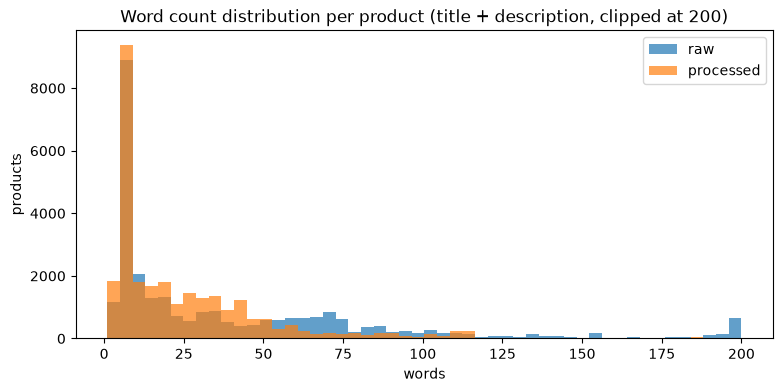

Average title length: 7.1 words
Average words per product (raw / processed): 40.7 / 24.5
Average sentences per description: 3.1
Average sentence length: 17.8 words
Products without description: 11150 (39.7%)


In [11]:
df["raw_words"] = (df["title"] + " " + df["description"]).map(lambda t: len(word_tokenize(t)))
df["processed_words"] = (df["title_tokens"] + df["description_tokens"]).map(len)
has_desc = df["description"].str.strip() != ""

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["raw_words"].clip(upper=200), bins=50, alpha=0.7, label="raw")
ax.hist(df["processed_words"].clip(upper=200), bins=50, alpha=0.7, label="processed")
ax.set_title("Word count distribution per product (title + description, clipped at 200)")
ax.set_xlabel("words"); ax.set_ylabel("products"); ax.legend()
plt.show()

sentences = [s for d in df.loc[has_desc, "description"] for s in sent_tokenize(d)]
print("Average title length:", round(df["title"].map(lambda t: len(word_tokenize(t))).mean(), 1), "words")
print("Average words per product (raw / processed):", round(df["raw_words"].mean(), 1), "/", round(df["processed_words"].mean(), 1))
print("Average sentences per description:", round(len(sentences) / has_desc.sum(), 1))
print("Average sentence length:", round(np.mean([len(word_tokenize(s)) for s in sentences]), 1), "words")
print("Products without description:", (~has_desc).sum(), f"({100 * (~has_desc).mean():.1f}%)")

### 2.2 Vocabulary size

In [12]:
text = df["title"] + " " + df["description"]
stages = {
    "raw (lowercase, split on spaces)": Counter(w for t in text for w in t.lower().split()),
    "pre-processed without stemming": Counter(w for t in text for w in preprocess(t, stem=False)),
    "pre-processed with stemming": Counter(w for toks in df["title_tokens"] + df["description_tokens"] for w in toks),
    "combined field (all text fields)": Counter(w for toks in df["tokens"] for w in toks),
}
pd.DataFrame({"vocabulary size": {k: len(v) for k, v in stages.items()},
              "total tokens": {k: sum(v.values()) for k, v in stages.items()}})

,vocabulary size,total tokens
"raw (lowercase, split on spaces)",10606,1017425
pre-processed without stemming,6124,686812
pre-processed with stemming,4654,686812
combined field (all text fields),5058,1071229


### 2.3 Most frequent words and word clouds

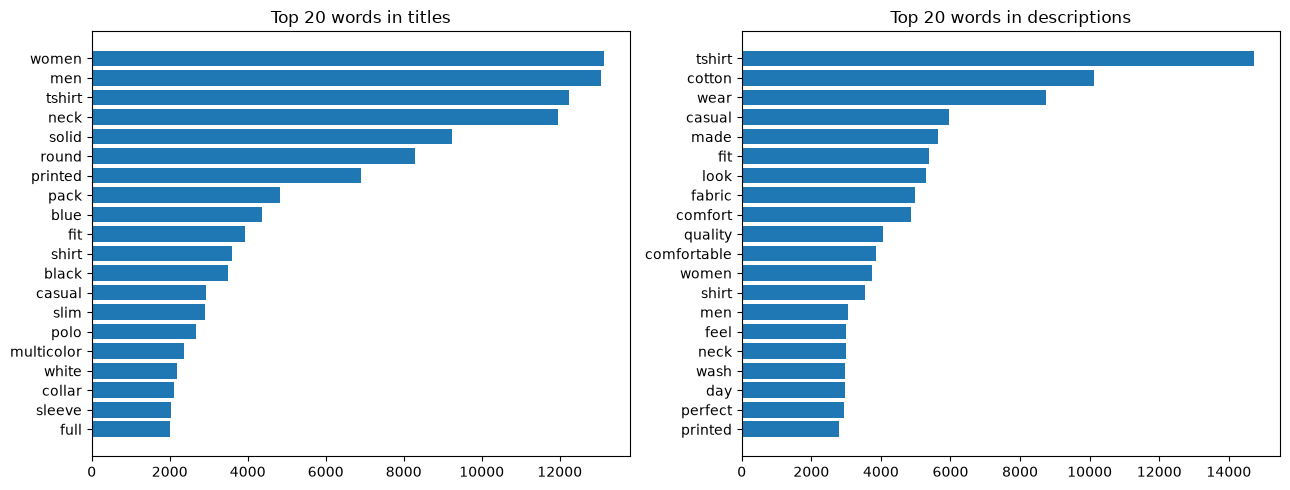

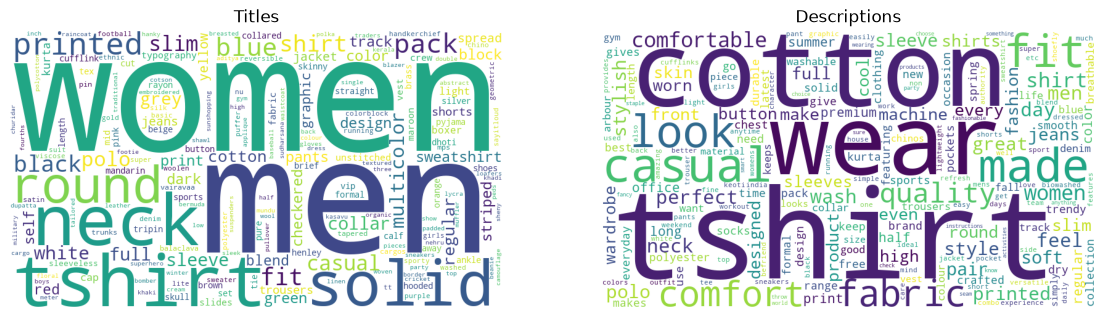

In [13]:
title_freq = Counter(w for t in df["title"] for w in preprocess(t, stem=False))
desc_freq = Counter(w for t in df["description"] for w in preprocess(t, stem=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, freq, name in [(axes[0], title_freq, "titles"), (axes[1], desc_freq, "descriptions")]:
    words, counts = zip(*freq.most_common(20))
    ax.barh(words[::-1], counts[::-1])
    ax.set_title(f"Top 20 words in {name}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, freq, name in [(axes[0], title_freq, "Titles"), (axes[1], desc_freq, "Descriptions")]:
    ax.imshow(WordCloud(width=800, height=450, background_color="white", random_state=42).generate_from_frequencies(freq))
    ax.axis("off")
    ax.set_title(name)
plt.show()

### 2.4 Categories

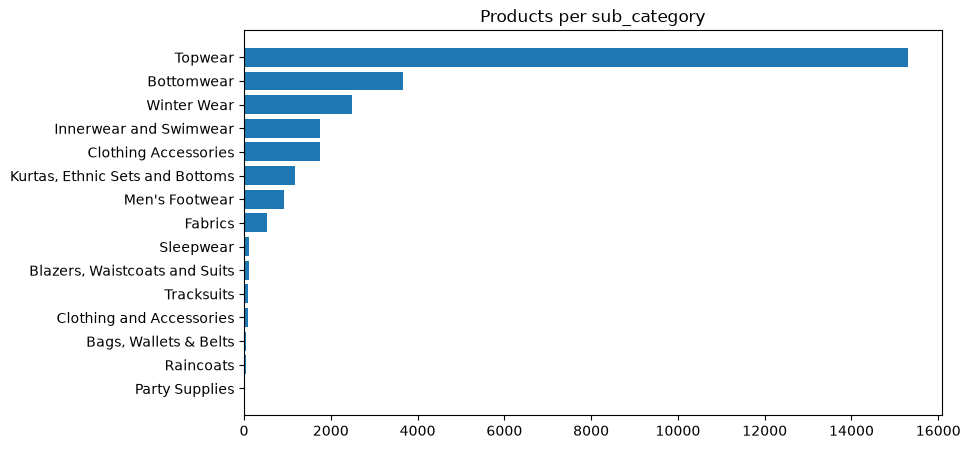

Distinct titles: 5953 (78.8% of titles are repeated)


title
Slides                                      544
Printed Men Round Neck Black T-Shirt        418
Printed Women Round Neck Black T-Shirt      396
Printed Women Round Neck White T-Shirt      349
Rayon Printed Shirt Fabric  (Unstitched)    343
Printed Men Round Neck White T-Shirt        323
Full Sleeve Solid Men Sweatshirt            214
Full Sleeve Solid Women Sweatshirt          204
Printed Women Round Neck Blue T-Shirt       189
Full Sleeve Printed Men Sweatshirt          184
Name: count, dtype: int64

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sc = df["sub_category"].value_counts()
ax.barh(sc.index[::-1], sc.values[::-1])
ax.set_title("Products per sub_category")
plt.show()
print("Distinct titles:", df["title"].nunique(), f"({100 * df['title'].duplicated().mean():.1f}% of titles are repeated)")
df["title"].value_counts().head(10)

### 2.5 Prices, discounts and ratings

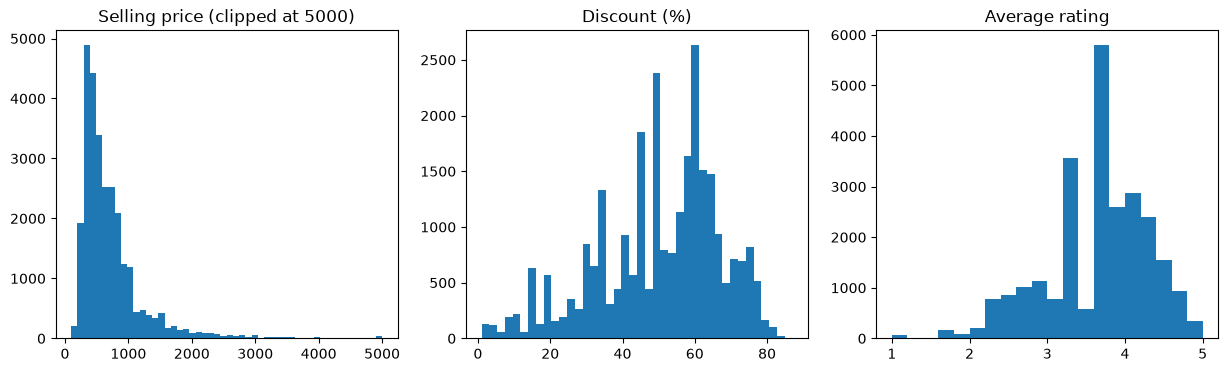

Correlation (Spearman)


,selling_price,actual_price,discount,average_rating
selling_price,1.00,0.77,-0.37,-0.03
actual_price,0.77,1.00,0.26,-0.09
discount,-0.37,0.26,1.00,-0.10
average_rating,-0.03,-0.09,-0.10,1.00


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["selling_price"].dropna().clip(upper=5000), bins=50)
axes[0].set_title("Selling price (clipped at 5000)")
axes[1].hist(df["discount"].dropna(), bins=40)
axes[1].set_title("Discount (%)")
axes[2].hist(df["average_rating"].dropna(), bins=20)
axes[2].set_title("Average rating")
plt.show()

print("Correlation (Spearman)")
df[["selling_price", "actual_price", "discount", "average_rating"]].corr(method="spearman").round(2)

In [16]:
cols = ["pid", "title", "brand", "selling_price", "discount", "average_rating"]
print("Top 10 by rating")
display(df.sort_values(["average_rating", "discount"], ascending=False)[cols].head(10))
print("Top 10 most expensive")
display(df.sort_values("selling_price", ascending=False)[cols].head(10))
print("Top 10 cheapest")
display(df.sort_values("selling_price")[cols].head(10))
print("Top 10 by discount")
display(df.sort_values("discount", ascending=False)[cols].head(10))

Top 10 by rating


,pid,title,brand,selling_price,discount,average_rating
22441,KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),Purple Sta,449.0,82.0,5.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,249.0,78.0,5.0
17993,TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,275.0,77.0,5.0
18497,TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,PixF,289.0,77.0,5.0
18503,TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,288.0,77.0,5.0
18543,TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,PixF,288.0,77.0,5.0
18714,TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,PixF,288.0,77.0,5.0
18738,TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,PixF,288.0,77.0,5.0
18757,TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,PixF,288.0,77.0,5.0
18781,TSHFTT2SZVYFXHJV,Printed Women Round Neck Red T-Shirt,PixF,288.0,77.0,5.0


Top 10 most expensive


,pid,title,brand,selling_price,discount,average_rating
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,20.0,2.7
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,True Bl,7998.0,NaN,2.6
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,40.0,4.5
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,40.0,3.7
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,40.0,4.2
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full S...,True Bl,6998.0,NaN,2.6
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,6925.0,36.0,4.5
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,6692.0,39.0,3.8
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,6499.0,50.0,3.7
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,6493.0,35.0,NaN


Top 10 cheapest


,pid,title,brand,selling_price,discount,average_rating
16485,SOCET7QRNHYG9HHB,Women Mid-Calf/Crew (Pack of 2),Welwe,99.0,50.0,3.8
20435,BDAFUBD2EJHFCRNC,Men Printed Bandana,T10 Spor,99.0,50.0,2.4
7654,SOCFFGA2FYZQBFXT,Women Color Block Ankle Length (Pack of 3),your shopping sto,118.0,76.0,3.9
24438,SOCFZ7GFAZGYZGR7,Men Solid Ankle Length (Pack of 3),ina gro,120.0,69.0,NaN
24437,SOCFZAGJC3VUFQU9,Women Solid Ankle Length (Pack of 3),ina gro,120.0,69.0,NaN
24439,SOCFZ7JX39ZEW8GE,Women Solid Ankle Length (Pack of 3),ina gro,120.0,69.0,NaN
20253,CAPEX5YHPH3MSGFC,Cotton 5 panel baseball Cap,T10 Spor,124.0,50.0,2.3
16402,SUSECSFFVNKG5VGG,Brand Trunk Y- Back Suspenders for Men (Black),,125.0,74.0,4.1
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,87.0,3.0
25325,SOCFPR9UF8Q4FCHG,Men Ankle Length (Pack of 3),Pu,132.0,73.0,3.7


Top 10 by discount


,pid,title,brand,selling_price,discount,average_rating
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,87.0,3.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,136.0,86.0,4.7
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,136.0,86.0,4.1
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvib,449.0,85.0,3.2
9811,CAPE9YWMSVSZPM2K,Solid Balclava Cap,Gracew,228.0,84.0,4.3
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,280.0,84.0,3.4
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,282.0,84.0,4.2
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,230.0,84.0,4.6
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),,499.0,84.0,2.7
3102,TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,REF,228.0,84.0,4.2


### 2.6 Top brands and sellers

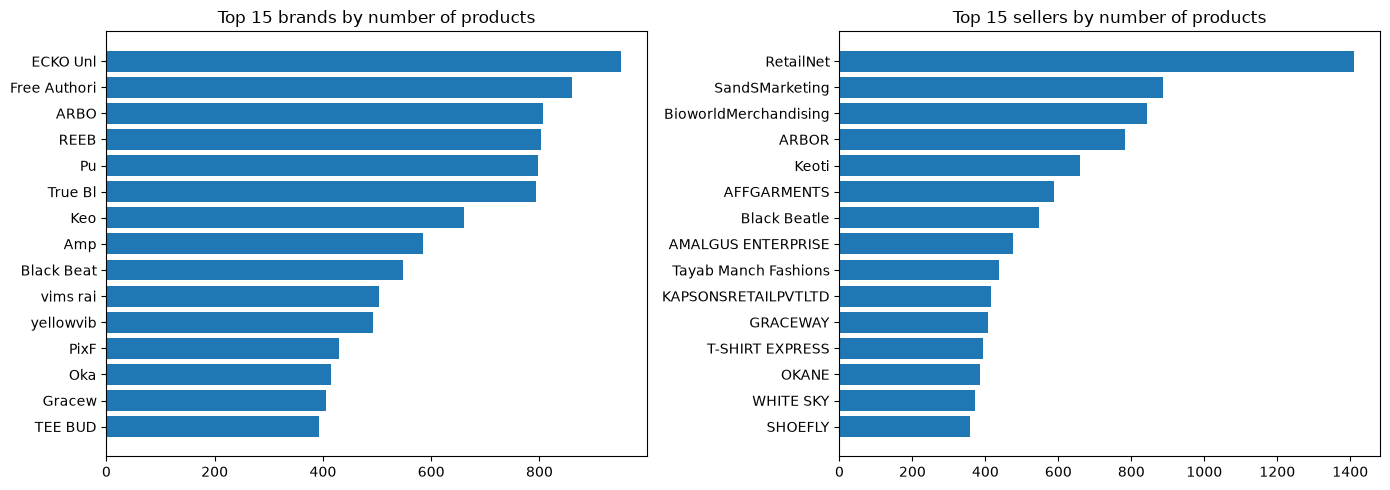

Distinct brands: 324 | distinct sellers: 534
Best-rated brands (at least 100 products)


,products,avg_rating,avg_price
brand,,,
PixF,429,4.46,305.03
Cots,277,4.44,356.88
Zack Fo,128,4.33,571.20
Gracew,405,4.23,412.07
Marca Disa,353,4.19,582.79
Byford by Pantaloo,179,4.11,736.54
ARBO,806,4.10,431.58
TOM BU,290,4.10,487.35
Pu,798,4.06,1514.65


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["brand", "seller"]):
    top = df.loc[df[col] != "", col].value_counts().head(15)
    ax.barh(top.index[::-1], top.values[::-1])
    ax.set_title(f"Top 15 {col}s by number of products")
plt.tight_layout()
plt.show()

print("Distinct brands:", df.loc[df["brand"] != "", "brand"].nunique(), "| distinct sellers:", df.loc[df["seller"] != "", "seller"].nunique())
print("Best-rated brands (at least 100 products)")
(df[df["brand"] != ""].groupby("brand")
   .agg(products=("pid", "count"), avg_rating=("average_rating", "mean"), avg_price=("selling_price", "mean"))
   .query("products >= 100").sort_values("avg_rating", ascending=False).round(2).head(10))

### 2.7 out_of_stock distribution

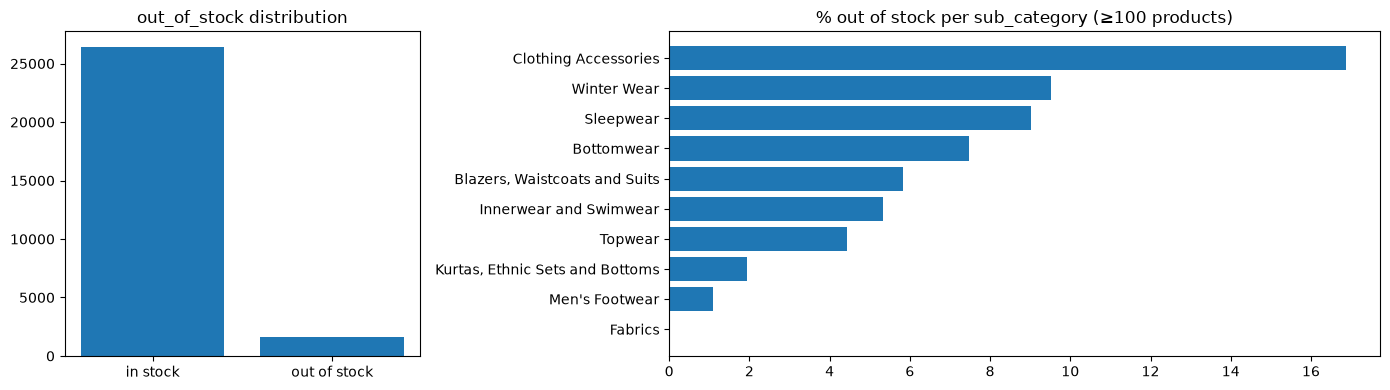

out_of_stock
False    94.1
True      5.9
Name: proportion, dtype: float64


In [18]:
counts = df["out_of_stock"].value_counts()
by_sub = df.groupby("sub_category")["out_of_stock"].agg(["mean", "count"]).query("count >= 100").sort_values("mean")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(["in stock", "out of stock"], [counts[False], counts[True]])
axes[0].set_title("out_of_stock distribution")
axes[1].barh(by_sub.index, 100 * by_sub["mean"])
axes[1].set_title("% out of stock per sub_category (≥100 products)")
plt.tight_layout()
plt.show()
print((100 * df["out_of_stock"].value_counts(normalize=True)).round(1))

### 2.8 Entity recognition

NLTK named-entity chunker on a sample of 500 distinct non-empty descriptions. The model is trained on news text, so on product descriptions it is noisy
(fabrics or product words are often tagged as PERSON/ORGANIZATION); brands and places (*India*) are recognised reasonably well.

In [19]:
sample = df.loc[has_desc, "description"].drop_duplicates().sample(500, random_state=42)
entities = Counter()
for text_ in sample:
    for chunk in ne_chunk(pos_tag(word_tokenize(text_))):
        if hasattr(chunk, "label"):
            entities[(chunk.label(), " ".join(w for w, _ in chunk))] += 1

type_counts = Counter()
for (label, _), n in entities.items():
    type_counts[label] += n
print("Entity types:", dict(type_counts.most_common()))
pd.DataFrame([(l, e, n) for (l, e), n in entities.most_common(20)], columns=["type", "entity", "count"])

Entity types: {'PERSON': 1063, 'ORGANIZATION': 514, 'GPE': 334, 'FACILITY': 27, 'LOCATION': 2, 'GSP': 1}


,type,entity,count
0,PERSON,Cotton,55
1,ORGANIZATION,ECKO,37
2,GPE,Women,18
3,PERSON,Single Jersey Fabric,17
4,GPE,Casual,17
5,PERSON,Free Authority,17
6,PERSON,Free,17
7,GPE,Look,16
8,GPE,Men,15
9,PERSON,Full Sleeve,15


## Summary of findings

- 28,080 products, no duplicated pid. 39.7% have no description, so title and product_details are essential for retrieval.
- Titles are short (~7 words) and very repetitive: only 5,953 distinct titles (78.8% repeated) → many ties in scoring; numeric fields (rating, discount, stock) can help to break them in Part 3.
- category is almost constant (96.6% Clothing and Accessories); Topwear dominates sub_category (55%).
- Pre-processing reduces the title+description vocabulary from 10,606 to 4,654 terms and the number of tokens per product from 40.7 to 24.5.
- Selling prices are mostly between ₹390 and ₹820 (median ₹545); the average discount is 50%; average rating 3.63 (8% of products have no rating). Rating is practically uncorrelated with price and discount.
- 324 brands and 534 sellers; 5.9% of products are out of stock (highest in Clothing Accessories).
- NER with NLTK is noisy on product text (fabrics/product words tagged as PERSON), but brands and places are detected.
- The validation queries show that the title is the most discriminative field and that product_details contains terms (e.g. cotton) missing from the title.